# 9주차 · 기본 정렬 구현 및 비교
## 학생 배포용: TODO 구현·테스트·성능 실험
데이터구조 | 임화정 | Python 3.8+

학습목표: 버블·선택·삽입 정렬을 구현하고, 불변식·안정성·시간/보조공간 복잡도를 설명하며 동일 입력의 성능을 측정한다.

강의계획서의 9주차 목표와 2주차 Big-O, 7주차 BST/TreeSort를 연결한다. 기존 자료의 개념→구현→검증→성능 분석 흐름을 따른다.

사용법: 위에서 아래로 실행한다. 학생용은 미구현 함수를 안내하고 해당 실험을 건너뛴다. TODO 완료 뒤 구현·테스트·실험 셀을 다시 실행한다.

권장 150분 수업: 개념/추적 50분, 구현 45분, 실험 35분, 토론/정리 20분(휴식 별도).

In [1]:
import random
import time
import statistics
import csv
from collections import Counter
SEED = 2026
# Python 3.8+ / Colab / Jupyter. 그래프 셀만 matplotlib가 필요합니다.
print("9주차 실습 준비 완료")

9주차 실습 준비 완료


## 1. 공통 인터페이스와 사전 예측
`sort(a, key=lambda x:x)`는 리스트 자체를 오름차순으로 변경하고 동일한 리스트를 반환한다. 반환값 복사 금지. `sorted`/`list.sort`는 구현에 사용하지 않고 정답 검증에만 사용한다.

버블은 인접 교환, 선택은 최소값 선택, 삽입은 정렬된 접두부에 삽입한다. 핵심 구현의 보조공간은 O(1); 실험용 복사·추적 기록은 별도 O(n) 이상이다. key 호출/비교는 O(1)이라고 가정한다.

**예측**: 이미 정렬된 입력에 가장 유리한 것은? 선택 정렬도 빨라질까?

## bubble_sort 구현
각 패스 뒤 최댓값이 오른쪽에 확정됩니다. end를 줄이고 교환이 없으면 종료. > 비교는 동점 순서를 유지합니다.

In [2]:
def bubble_sort(a, key=lambda x: x):
    n = len(a)
    for end in range(n - 1, 0, -1):          # a[end+1:]은 이미 확정된 큰 값들
        swapped = False
        for j in range(end):
            if key(a[j]) > key(a[j + 1]):    # > 비교: 동점은 교환하지 않아 안정
                a[j], a[j + 1] = a[j + 1], a[j]
                swapped = True
        if not swapped:                      # 교환이 없으면 이미 정렬됨 → 조기 종료
            break
    return a

## selection_sort 구현
i 이전 접두부가 확정됩니다. min_idx를 i로 초기화하고 나머지 구간을 모두 비교합니다. 최솟값과 한 번 교환. 일반 교환형 선택 정렬은 불안정합니다.

In [3]:
def selection_sort(a, key=lambda x: x):
    n = len(a)
    for i in range(n - 1):                   # a[:i]는 확정된 최솟값들
        min_idx = i
        for j in range(i + 1, n):            # 나머지 구간 전체에서 최솟값 탐색
            if key(a[j]) < key(a[min_idx]):
                min_idx = j
        if min_idx != i:                     # 최솟값과 한 번만 교환 (불안정 원인)
            a[i], a[min_idx] = a[min_idx], a[i]
    return a

## insertion_sort 구현
a[:i]가 정렬되어 있습니다. current를 저장하고 큰 원소만 오른쪽으로 이동합니다. j >= 0을 먼저 검사하여 음수 인덱스 접근을 막습니다.

In [4]:
def insertion_sort(a, key=lambda x: x):
    for i in range(1, len(a)):               # a[:i]는 정렬된 접두부
        current = a[i]
        k = key(current)
        j = i - 1
        while j >= 0 and key(a[j]) > k:      # j >= 0을 먼저 검사, 큰 원소만 오른쪽으로 이동
            a[j + 1] = a[j]
            j -= 1
        a[j + 1] = current                   # 빈 자리에 삽입
    return a

## 2. 정확성 검사
빈 입력·단일 원소·중복·음수·정렬/역순·고정 시드 무작위 입력. 결과 순서와 원소 보존, in-place 반환 계약을 확인한다.

In [5]:
algorithms = {"Bubble": bubble_sort, "Selection": selection_sort, "Insertion": insertion_sort}
def test_sort(fn):
    cases = [[], [1], [2, 1], [1, 2, 3], [3, 2, 1], [2, 2, 1, 2], [-3, 0, -1, 5]]
    rng = random.Random(SEED)
    cases += [[rng.randrange(-20, 21) for _ in range(n)] for n in range(41)]
    for original in cases:
        a = original.copy()
        returned = fn(a)
        assert returned is a, "반환값은 입력 리스트 자체여야 합니다."
        assert a == sorted(original), (original, a)
        assert Counter(a) == Counter(original)
    return len(cases)
ready = {}
for name, fn in algorithms.items():
    try:
        print(name, test_sort(fn), "개 테스트 통과")
        ready[name] = fn
    except NotImplementedError:
        print(name, "TODO 구현 후 이 셀을 다시 실행하세요.")
assert len(ready) in range(4)

Bubble 48 개 테스트 통과
Selection 48 개 테스트 통과
Insertion 48 개 테스트 통과


## 3. 패스 추적
[5, 1, 4, 2, 8]의 각 패스 결과를 먼저 손으로 작성하라.

**학생 답안**

- **버블** (각 패스 뒤 최댓값이 오른쪽에 확정)
  - 패스 1: [1, 4, 2, 5, 8] (5↔1, 5↔4, 5↔2 교환, 5<8 유지)
  - 패스 2: [1, 2, 4, 5, 8] (4↔2 교환)
  - 패스 3: [1, 2, 4, 5, 8] — 교환 없음 → 조기 종료
- **선택** (i번째 자리에 남은 구간의 최솟값)
  - i=0: [1, 5, 4, 2, 8] (최솟값 1과 5 교환)
  - i=1: [1, 2, 4, 5, 8] (최솟값 2와 5 교환)
  - i=2: [1, 2, 4, 5, 8] (4가 이미 최솟값, 교환 없음)
  - i=3: [1, 2, 4, 5, 8] (5가 이미 최솟값, 교환 없음)
- **삽입** (a[:i]가 정렬된 접두부)
  - i=1: [1, 5, 4, 2, 8] (1 삽입, 5 이동)
  - i=2: [1, 4, 5, 2, 8] (4 삽입, 5 이동)
  - i=3: [1, 2, 4, 5, 8] (2 삽입, 5·4 이동)
  - i=4: [1, 2, 4, 5, 8] (8은 이동 없음)


## 4. 안정성 실험
동일 키의 원래 상대 순서가 유지되는가? 아래 기록을 첫 번째 필드만으로 정렬하고 A/B 순서를 관찰하라. 선택 정렬이 불안정한 이유를 설명하라.

In [6]:
records = [(2, "A"), (2, "B"), (1, "C")]
for name, fn in ready.items():
    a = records.copy()
    fn(a, key=lambda r: r[0])
    print(name, a, "동점 순서 유지:", [r[1] for r in a if r[0] == 2] == ["A", "B"])
# 튜플 전체가 아니라 첫 번째 필드만 비교해야 안정성을 검증할 수 있습니다.

Bubble [(1, 'C'), (2, 'A'), (2, 'B')] 동점 순서 유지: True
Selection [(1, 'C'), (2, 'B'), (2, 'A')] 동점 순서 유지: False
Insertion [(1, 'C'), (2, 'A'), (2, 'B')] 동점 순서 유지: True


## 5. 연산 횟수와 복잡도
아래 계측기는 키 비교만 comparisons로 센다. 인덱스 검사 제외. swap은 두 원소 교환 1회, shift는 삽입 정렬의 오른쪽 이동 1회다. swap과 shift는 서로 같은 비용 단위가 아니며 전체 쓰기 횟수도 아니다. 계측기 함수는 측정용 모형이며 실행 시간 비교에는 사용하지 않는다.

In [7]:
def count_operations(data, kind):
    a = data.copy()
    comparisons = swaps = shifts = 0
    n = len(a)
    if kind == "Bubble":
        for end in range(n - 1, 0, -1):
            changed = False
            for j in range(end):
                comparisons += 1
                if a[j] > a[j + 1]:
                    a[j], a[j + 1] = a[j + 1], a[j]
                    swaps += 1
                    changed = True
            if not changed: break
    elif kind == "Selection":
        for i in range(n - 1):
            m = i
            for j in range(i + 1, n):
                comparisons += 1
                if a[j] < a[m]: m = j
            if m != i:
                a[i], a[m] = a[m], a[i]
                swaps += 1
    elif kind == "Insertion":
        for i in range(1, n):
            current = a[i]
            j = i - 1
            while j >= 0:
                comparisons += 1
                if a[j] <= current: break
                a[j + 1] = a[j]
                shifts += 1
                j -= 1
            a[j + 1] = current
    else:
        raise ValueError(kind)
    assert a == sorted(data)
    return {"comparisons": comparisons, "swaps": swaps, "shifts": shifts}
for kind in algorithms:
    for label, data in [("sorted", list(range(8))), ("reverse", list(range(7, -1, -1)))]:
        print(kind, label, count_operations(data, kind))
assert count_operations(list(range(8)), "Bubble")["comparisons"] == 7
assert count_operations(list(range(8)), "Selection")["comparisons"] == 28
assert count_operations(list(range(7, -1, -1)), "Insertion")["shifts"] == 28

Bubble sorted {'comparisons': 7, 'swaps': 0, 'shifts': 0}
Bubble reverse {'comparisons': 28, 'swaps': 28, 'shifts': 0}
Selection sorted {'comparisons': 28, 'swaps': 0, 'shifts': 0}
Selection reverse {'comparisons': 28, 'swaps': 4, 'shifts': 0}
Insertion sorted {'comparisons': 7, 'swaps': 0, 'shifts': 0}
Insertion reverse {'comparisons': 28, 'swaps': 0, 'shifts': 28}


### 분석 질문
1. 선택 정렬 비교 횟수 n(n−1)/2를 유도하라.
2. 조기 종료 버블의 최선 Θ(n), 최악 Θ(n²)를 설명하라.
3. 삽입 정렬의 shift 횟수와 역전쌍 수의 관계는?
4. n=8 정렬/역순에서 각 비교·교환·이동 횟수를 기록하라.

**학생 답안**

1. i번째 단계(i = 0 … n−2)에서 남은 구간 a[i+1..n−1]의 원소 n−1−i개를 모두 min과 비교한다. 입력과 무관하게 항상 같으므로 총 비교 = (n−1) + (n−2) + … + 1 = n(n−1)/2 = Θ(n²). (n=8 → 28, 실측과 일치)
2. **최선**: 이미 정렬된 입력이면 첫 패스에서 n−1번 비교하고 교환이 한 번도 없어 즉시 종료 → Θ(n). (n=8 → 비교 7)
   **최악**: 역순 입력이면 매 패스마다 교환이 일어나 조기 종료가 안 되고, 패스 크기가 n−1, n−2, …, 1 → 비교 n(n−1)/2 = Θ(n²). (n=8 → 비교 28, 교환 28)
3. 삽입 정렬의 shift 1회는 인접한 역전쌍(i<j, a[i]>a[j]) 하나를 정확히 제거한다. 따라서 **shift 횟수 = 입력의 역전쌍 수 I**이고, 비교 횟수는 I 이상 I+(n−1) 이하이다. 실행 시간은 Θ(n + I) → 거의 정렬된 입력(I가 작음)에서 매우 빠르고, 역순(I = n(n−1)/2)에서 최악이다. (버블의 swap 수도 역전쌍 수와 같다.)
4. n=8 실측 결과

|알고리즘|입력|비교|교환(swap)|이동(shift)|
|---|---|---|---|---|
|버블|정렬|7|0|0|
|버블|역순|28|28|0|
|선택|정렬|28|0|0|
|선택|역순|28|4|0|
|삽입|정렬|7|0|0|
|삽입|역순|28|0|28|

선택 정렬은 비교 수가 입력과 무관하게 28로 고정이지만 교환은 최대 n−1회(역순 8개에서는 대칭쌍 4회)로 가장 적다.


## 6. 공정한 실행 시간 측정
5개 입력 유형 × 4개 크기 × 3개 알고리즘. 고정 시드·동일 데이터·실행 전 복사·워밍업·5회 반복·중앙값. 시계는 perf_counter_ns. 생성/복사/검증/I/O 비용 제외. 키 함수는 공통으로 사용하므로 키 호출 오버헤드가 포함된다. 시간이 작은 경우 잡음이 크다. 환경마다 수치는 달라지며 한 번의 실측으로 Big-O를 증명할 수 없다. 거의 정렬된 입력은 인접 교환으로 생성된다.

In [8]:
def make_data(n, pattern, seed):
    rng = random.Random(seed)
    if pattern == "random": return [rng.randrange(n * 10 + 1) for _ in range(n)]
    if pattern == "sorted": return list(range(n))
    if pattern == "reverse": return list(range(n - 1, -1, -1))
    if pattern == "duplicates": return [rng.randrange(5) for _ in range(n)]
    if pattern == "nearly_sorted":
        a = list(range(n))
        for _ in range(max(1, n // 20)):
            if n > 1:
                j = rng.randrange(n - 1)
                a[j], a[j + 1] = a[j + 1], a[j]
        return a
    raise ValueError(pattern)
SIZES = [100, 200, 400, 800]  # 처음에는 작게; 큰 n은 O(n²)로 오래 걸립니다.
PATTERNS = ["random", "sorted", "reverse", "nearly_sorted", "duplicates"]
REPEATS = 5
results = []
if len(ready) != 3:
    print("세 알고리즘 구현 및 테스트를 완료하면 성능 비교가 실행됩니다.")
else:
    for pattern in PATTERNS:
        for n in SIZES:
            data = make_data(n, pattern, SEED + n)
            expected = sorted(data)  # 정답 생성은 측정 밖
            rng = random.Random(SEED + n)
            samples = {name: [] for name in ready}
            for fn in ready.values(): fn(data.copy())  # 워밍업
            for _ in range(REPEATS):
                names = list(ready)
                rng.shuffle(names)  # 실행 순서 편향 완화
                for name in names:
                    a = data.copy()  # 복사 비용은 측정 제외
                    start = time.perf_counter_ns()
                    ready[name](a)
                    elapsed = time.perf_counter_ns() - start
                    assert a == expected  # 검증도 측정 제외
                    samples[name].append(elapsed / 1_000_000)
            for name, values in samples.items():
                results.append({"pattern": pattern, "n": n, "algorithm": name,
                                "median_ms": statistics.median(values),
                                "min_ms": min(values), "max_ms": max(values)})
    with open("benchmark.csv", "w", newline="", encoding="utf-8-sig") as f:
        writer = csv.DictWriter(f, fieldnames=list(results[0]))
        writer.writeheader(); writer.writerows(results)
    for row in results[:9]: print(row)
    print("전체 결과: week09_benchmark.csv", len(results), "행")

{'pattern': 'random', 'n': 100, 'algorithm': 'Bubble', 'median_ms': 0.750916, 'min_ms': 0.699125, 'max_ms': 0.800625}
{'pattern': 'random', 'n': 100, 'algorithm': 'Selection', 'median_ms': 0.472, 'min_ms': 0.442625, 'max_ms': 0.485}
{'pattern': 'random', 'n': 100, 'algorithm': 'Insertion', 'median_ms': 0.338792, 'min_ms': 0.307625, 'max_ms': 0.433667}
{'pattern': 'random', 'n': 200, 'algorithm': 'Bubble', 'median_ms': 2.5425, 'min_ms': 2.432417, 'max_ms': 2.804791}
{'pattern': 'random', 'n': 200, 'algorithm': 'Selection', 'median_ms': 1.90825, 'min_ms': 1.775792, 'max_ms': 1.955125}
{'pattern': 'random', 'n': 200, 'algorithm': 'Insertion', 'median_ms': 1.16725, 'min_ms': 1.159959, 'max_ms': 1.240542}
{'pattern': 'random', 'n': 400, 'algorithm': 'Bubble', 'median_ms': 9.607917, 'min_ms': 7.41875, 'max_ms': 10.797667}
{'pattern': 'random', 'n': 400, 'algorithm': 'Selection', 'median_ms': 6.330625, 'min_ms': 5.993334, 'max_ms': 7.707209}
{'pattern': 'random', 'n': 400, 'algorithm': 'Inser

## 7. 성능 시각화
아래 그래프는 현재 실행에서 측정한 중앙값만 사용한다. 범례와 단위를 확인하고 유형별로 비교하라.

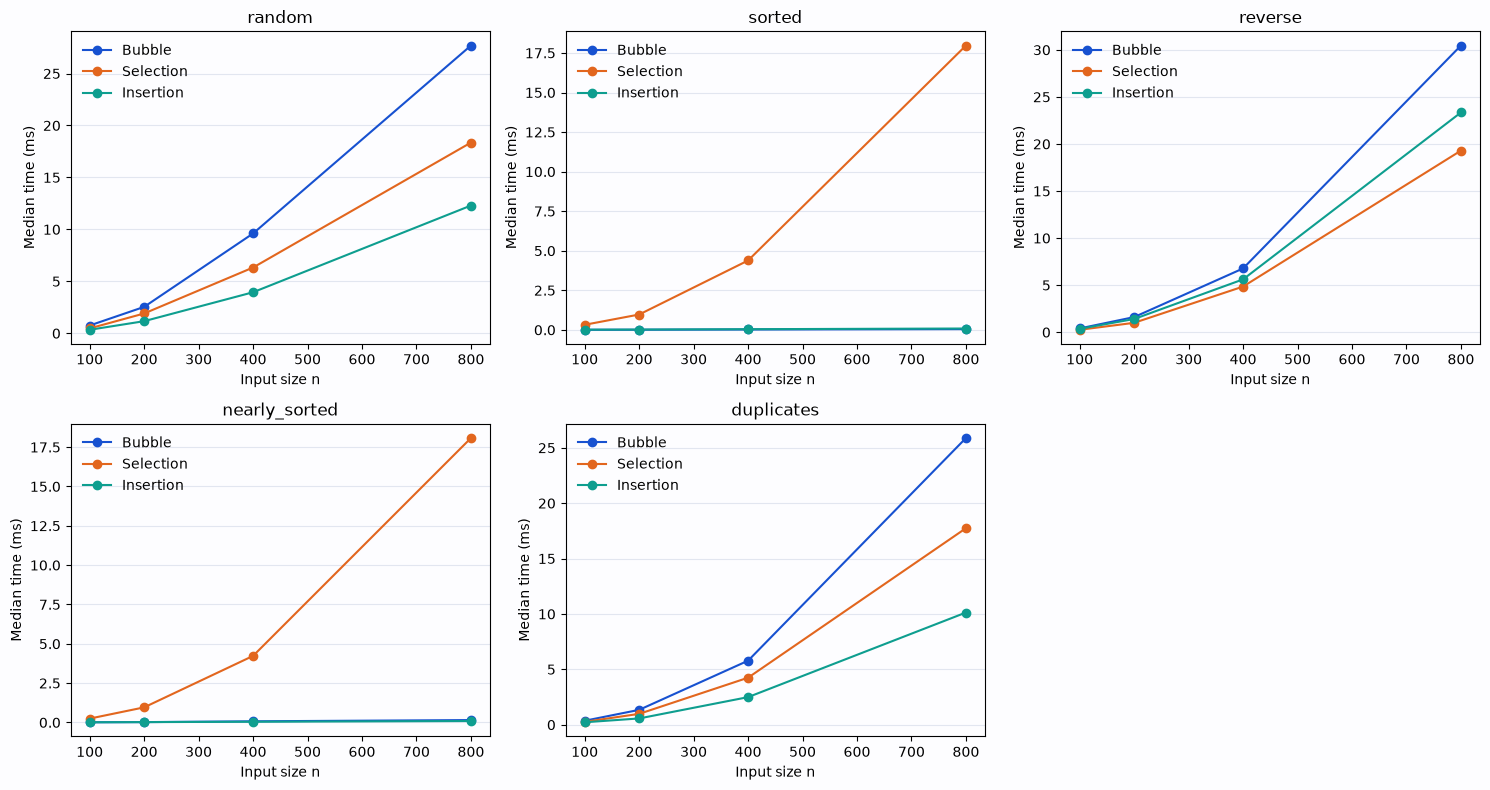

In [9]:
if results:
    try:
        import matplotlib.pyplot as plt
        try:
            import koreanize_matplotlib
        except ImportError:
            pass  # 그래프 라벨은 영문이므로 Colab에서도 실행 가능
        colors = ["#1751D0", "#E2661E", "#0E9E8F"]
        fig, axes = plt.subplots(2, 3, figsize=(15, 8), facecolor="#FDFDFF")
        for ax, pattern in zip(axes.flat, PATTERNS):
            ax.set_facecolor("#FDFDFF")
            for color, name in zip(colors, algorithms):
                rows = sorted([r for r in results if r["pattern"] == pattern and r["algorithm"] == name], key=lambda r:r["n"])
                ax.plot([r["n"] for r in rows], [r["median_ms"] for r in rows], marker="o", color=color, label=name)
            ax.set(title=pattern, xlabel="Input size n", ylabel="Median time (ms)")
            ax.grid(axis="y", color="#E2E6F0"); ax.set_axisbelow(True)
            ax.legend(frameon=False)
        axes.flat[-1].axis("off")
        fig.tight_layout()
        fig.savefig("benchmark.png", dpi=150)
        plt.show()
    except ImportError:
        print("matplotlib가 없어 그래프를 건너뜁니다. Colab에서 실행하거나 CSV를 활용하세요.")
else:
    print("구현 완료 후 성능 측정 셀부터 다시 실행하세요.")

## 8. 결과 분석 및 제출
- 무작위/역순에서 n을 두 배로 늘릴 때 시간 비율 T(2n)/T(n)은?
- 정렬 입력의 버블·삽입과 선택은 어떻게 다른가?
- 안정성과 이동 횟수는 어떤 문제에서 중요한가?
- nearly_sorted 결과를 역전쌍 관점에서 설명하라.
- 이론과 실측이 다른 이유 2가지를 적어라.

**답안** (아래 수치는 본 실행 환경의 중앙값, 단위 ms. 환경마다 달라질 수 있음)

**실측 표 요약**

|입력|알고리즘|n=100|n=200|n=400|n=800|T(800)/T(400)|
|---|---|---|---|---|---|---|
|random|Bubble|0.391|1.604|6.392|27.578|4.31|
|random|Selection|0.284|1.047|4.381|17.908|4.09|
|random|Insertion|0.188|0.736|2.909|11.996|4.12|
|sorted|Bubble|0.006|0.011|0.024|0.050|2.08|
|sorted|Selection|0.244|0.952|4.178|17.263|4.13|
|sorted|Insertion|0.011|0.021|0.043|0.088|2.05|
|reverse|Bubble|0.390|1.517|6.541|28.761|4.40|
|reverse|Selection|0.261|1.037|4.385|18.385|4.19|
|reverse|Insertion|0.364|1.362|5.695|22.824|4.01|
|nearly_sorted|Bubble|0.012|0.022|0.070|0.146|2.09|
|nearly_sorted|Selection|0.236|0.934|4.182|17.385|4.16|
|nearly_sorted|Insertion|0.011|0.021|0.045|0.090|2.00|
|duplicates|Bubble|0.383|1.382|6.001|24.870|4.14|
|duplicates|Selection|0.257|1.012|4.197|17.219|4.10|
|duplicates|Insertion|0.169|0.546|2.463|9.706|3.94|

- **T(2n)/T(n)**: random·reverse에서 세 알고리즘 모두 약 4배(3.9~4.4) → n²에 비례하는 Θ(n²) 성장과 일치한다.
- **정렬 입력**: 버블(조기 종료)과 삽입은 비율이 약 2배로 Θ(n)이며 n=800에서도 0.1 ms 미만이다. 선택 정렬은 입력 상태와 무관하게 항상 n(n−1)/2번 비교하므로 정렬 입력에서도 random과 거의 같은 17 ms가 걸려 빨라지지 않는다. → 사전 예측의 답: 정렬 입력에는 버블·삽입이 유리하고, 선택은 빨라지지 않는다.
- **안정성과 이동 횟수의 중요성**: 안정성은 여러 키로 차례로 정렬할 때(예: 이름순 정렬 후 학점순으로 다시 정렬해 같은 학점 안에서 이름순 유지), 데이터베이스 레코드·성적표처럼 동일 키의 원래 순서가 의미를 가질 때 중요하다. 안정성 실험에서 선택 정렬은 (2,A),(2,B) 순서를 (2,B),(2,A)로 뒤집었는데, 멀리 떨어진 최솟값과 교환하면서 동일 키 원소를 다른 동일 키 원소 너머로 건너뛰게 하기 때문이다. 이동(쓰기) 횟수는 원소가 크거나 쓰기 비용이 비싼 경우(플래시 메모리, 큰 레코드 복사)에 중요하며, 이때는 교환이 최대 n−1회인 선택 정렬이 유리하다.
- **nearly_sorted (역전쌍 관점)**: 인접 교환 n/20번으로 만들었으므로 역전쌍 수 I ≤ n/20으로 매우 작다. 삽입 정렬은 Θ(n + I)이므로 거의 선형(0.090 ms)이고 sorted와 차이가 거의 없다. 버블도 swap 수 = I로 작고 몇 번의 패스만에 조기 종료되지만, 작은 원소가 왼쪽으로 패스당 한 칸씩만 이동하므로 패스 수가 늘어 삽입보다 약간 느리다(0.146 ms). 선택은 I와 무관하게 Θ(n²)이다.
- **duplicates**: 값이 5종류뿐이라 동일 값끼리는 역전쌍이 아니므로 random보다 역전쌍 수가 약간 적고, 삽입 정렬이 가장 빠르다(9.7 ms).
- **이론과 실측이 다른 이유**
  1. Big-O는 상수 계수와 저차항을 무시한다. 세 알고리즘 모두 random에서 Θ(n²)이지만 버블은 비교마다 교환(3번의 쓰기)과 key 호출이 많아 상수가 커서 삽입보다 약 2.3배 느리다. 같은 Θ(n²)이라도 실제 시간은 다르다.
  2. 측정 환경의 잡음: 인터프리터 오버헤드(key 람다 호출, 인덱싱), CPU 캐시·클럭 변동, OS 스케줄링, 가비지 컬렉션 등이 시간에 영향을 주며, 특히 n이 작아 0.01 ms 수준일 때는 상대 오차가 크다. 그래서 반복 측정의 중앙값을 사용했고, 한 번의 실측으로 Big-O를 증명할 수 없다.

**그래프 해석**: random·reverse·duplicates 그래프에서 세 곡선 모두 n에 대해 위로 휘는 포물선(이차) 형태이며 Bubble > Selection > Insertion 순으로 느리다(reverse에서는 삽입이 매 원소를 끝까지 이동하므로 Selection보다 느려짐). sorted·nearly_sorted 그래프에서 Bubble·Insertion은 바닥에 붙은 거의 수평의 직선, Selection만 혼자 이차 곡선으로 올라간다.

**복잡도 근거**: 선택 정렬 비교 수 n(n−1)/2 고정 → 모든 입력에서 Θ(n²). 버블은 조기 종료로 최선 Θ(n), 최악 Θ(n²). 삽입은 Θ(n + 역전쌍 수)이므로 최선 Θ(n), 최악 Θ(n²). 실측 비율(정렬 입력 ≈2배, 무작위/역순 ≈4배)이 이를 뒷받침한다.

**선택 근거**: 작은 입력이나 거의 정렬된 데이터, 안정성이 필요한 경우에는 **삽입 정렬**을 선택한다(실측 전 유형에서 가장 빠르거나 비슷, 안정, 적응적). 쓰기 비용이 매우 비싸 교환 횟수를 최소화해야 할 때만 **선택 정렬**을 고려하고, 버블 정렬은 교육용 외에는 장점이 거의 없다. 큰 n에서는 Θ(n log n) 정렬(병합·퀵·Python의 Timsort)을 써야 한다.

제출: DS_09배포용.ipynb, benchmark.csv, benchmark.png, 분석문 포함.
lms 과제란에 제출


## 이론 요약 및 근거 자료
|알고리즘|최선|평균|최악|보조공간|안정성|
|---|---|---|---|---|---|
|버블(조기 종료)|Θ(n)|Θ(n²)|Θ(n²)|O(1)|안정|
|선택(교환형)|Θ(n²)|Θ(n²)|Θ(n²)|O(1)|불안정|
|삽입(이동형)|Θ(n)|Θ(n²)|Θ(n²)|O(1)|안정|
평균은 무작위 순열 등 일반적인 입력 가정. 본 주차 코드는 수업 목표에 맞춰 새로 작성하였다.

근거: 데이터구조 강의계획서(26-2) 2~3쪽, 02. 알고리즘 복잡도와 Big-O(성능 측정·시간/공간 구분), 07 이진 탐색 트리(BST)(불변식·트레이스·TreeSort·실측), 01/03/04/05/06 강의자료의 이론→Python 구현→검증 흐름.